# Sliding-Window Background Subtraction & Picasso Localisation

This notebook explores background estimation and single-molecule localisation on the dual-channel ONI Nanoimager SMLM dataset (`data/preprocessed_data/corrected.tif`):

1. **Crude Spatial Mean Subtraction (Baseline):** Subtracting the scalar frame mean leaves the large-scale Gaussian illumination profile and local cellular haze intact, causing false-positive gradient triggers in bright regions.
2. **Streaming Sliding-Window Temporal Median (`SlidingWindowMedian`):** A Numba-accelerated per-pixel running median over a 50-frame window cleanly separates the slowly varying background from fast-blinking fluorophores.
3. **Transient (Residual) vs. Persistent (Background) Emitter Decomposition & Overlay:** Because a temporal median of window length $W$ retains any feature present for at least $W/2$ frames, emitters that remain ON for $\ge 25$ frames are absorbed into the background image. Here we localise the **background-removed residual** and the **background image** separately with Picasso (`gausslq`) and overlay both populations on the original frame.
4. **Multi-Frame Statistics & DECODE Photon Conversion:** Sampling background and fitted spot brightness across 100 frames and converting from camera ADU to DECODE photon units.

## 1. Setup & Crude Spatial Mean Subtraction (Baseline)

In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from numba import njit
from picasso.localize import localize_frames

ROOT = Path.cwd().parent if Path.cwd().name == 'localisation_workflow' else Path.cwd()
path = ROOT / 'data' / 'preprocessed_data' / 'corrected.tif'
print(f'Loaded TIFF path: {path} (exists: {path.exists()})')

Loaded TIFF path: /Users/rohan/Documents/projects/mphys/data/preprocessed_data/corrected.tif (exists: True)


Channel shapes: (684, 428) (684, 428)


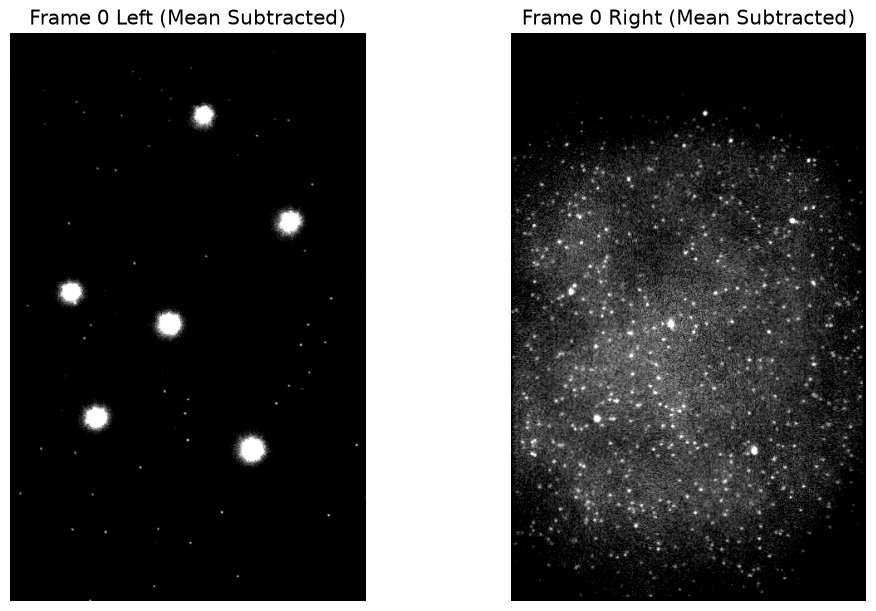

In [2]:
with Image.open(path) as image:
    image.seek(0)
    frame0 = np.asarray(image)

left, right = frame0[:, :428], frame0[:, 428:]
print('Channel shapes:', left.shape, right.shape)

left_centred = np.clip(left - left.mean(), 0, left.max()).astype(np.float32)
right_centred = np.clip(right - right.mean(), 0, right.max()).astype(np.float32)

display_max = np.percentile(np.concatenate([left_centred.ravel(), right_centred.ravel()]), 99.5)

fig, axes = plt.subplots(1, 2, figsize=(10, 6), constrained_layout=True)
axes[0].imshow(left_centred, cmap='gray', vmin=0, vmax=display_max)
axes[0].set_title('Frame 0 Left (Mean Subtracted)')
axes[0].axis('off')

axes[1].imshow(right_centred, cmap='gray', vmin=0, vmax=display_max)
axes[1].set_title('Frame 0 Right (Mean Subtracted)')
axes[1].axis('off')
plt.show()

In [3]:
# Picasso detection settings and ADU-equivalent camera dictionary
params = {
    'Box Size': 7,
    'Min. Net Gradient': 1000,
}

camera_info = {
    'Baseline': 0,
    'Sensitivity': 1.0,
    'Gain': 1,
    'Pixelsize': 117,  # nm
}

right_locs = localize_frames(
    right_centred[np.newaxis, :, :],
    info=None,
    params=params,
    camera_info=camera_info,
    fitting_method='gausslq',
    threaded=False,
)

print(f'Frame 0 Right (mean-subtracted): {len(right_locs)} localisations')
right_locs.head()

Frame 0 Right (mean-subtracted): 565 localisations


## 2. Streaming Sliding-Window Temporal Median (`SlidingWindowMedian`)

To remove spatially varying background without loading the entire 4,000-frame movie into memory, `SlidingWindowMedian` maintains a per-pixel dual heap (max-heap for the lower half, min-heap for the upper half) over a trailing window of `window_size = 50` frames.

> **Key Physical Property:** A temporal median of length $W = 50$ rejects transient fluorophore blinks that are ON for $< 25$ frames, but **absorbs any persistent emitter or fiducial bead that remains ON for $\ge 25$ frames** into `median_background`.

In [4]:
@njit
def _sift_down(heap, pixel, pos, size, is_max):
    while True:
        left = 2 * pos + 1
        if left >= size:
            break
        right = left + 1
        best = left
        if right < size and (heap[pixel, right] > heap[pixel, left]) == is_max:
            best = right
        if (heap[pixel, best] > heap[pixel, pos]) == is_max:
            heap[pixel, pos], heap[pixel, best] = heap[pixel, best], heap[pixel, pos]
            pos = best
        else:
            break


@njit
def _sift_up(heap, pixel, pos, is_max):
    while pos > 0:
        parent = (pos - 1) // 2
        if (heap[pixel, pos] > heap[pixel, parent]) == is_max:
            heap[pixel, pos], heap[pixel, parent] = heap[pixel, parent], heap[pixel, pos]
            pos = parent
        else:
            break


@njit
def _push(heap, pixel, size, value, is_max):
    heap[pixel, size] = value
    _sift_up(heap, pixel, size, is_max)


@njit
def _remove(heap, pixel, size, value, is_max):
    pos = 0
    while pos < size and heap[pixel, pos] != value:
        pos += 1
    if pos == size:
        raise ValueError('Expired value missing from heap')
    size -= 1
    if pos < size:
        heap[pixel, pos] = heap[pixel, size]
        if pos > 0 and (heap[pixel, pos] > heap[pixel, (pos - 1) // 2]) == is_max:
            _sift_up(heap, pixel, pos, is_max)
        else:
            _sift_down(heap, pixel, pos, size, is_max)


@njit
def _update_medians(lower, upper, history, values, slot, count, window_size):
    result = np.empty(values.size, dtype=np.float32)
    for pixel in range(values.size):
        n_lower = (count + 1) // 2
        n_upper = count // 2

        if count == window_size:
            old = history[slot, pixel]
            if old <= lower[pixel, 0]:
                _remove(lower, pixel, n_lower, old, True)
                n_lower -= 1
            else:
                _remove(upper, pixel, n_upper, old, False)
                n_upper -= 1

        value = values[pixel]
        if (n_lower > 0 and value <= lower[pixel, 0]) or (
            n_lower == 0 and (n_upper == 0 or value <= upper[pixel, 0])
        ):
            _push(lower, pixel, n_lower, value, True)
            n_lower += 1
        else:
            _push(upper, pixel, n_upper, value, False)
            n_upper += 1

        while n_lower > n_upper + 1:
            middle = lower[pixel, 0]
            _remove(lower, pixel, n_lower, middle, True)
            n_lower -= 1
            _push(upper, pixel, n_upper, middle, False)
            n_upper += 1
        while n_lower < n_upper:
            middle = upper[pixel, 0]
            _remove(upper, pixel, n_upper, middle, False)
            n_upper -= 1
            _push(lower, pixel, n_lower, middle, True)
            n_lower += 1

        history[slot, pixel] = value
        if n_lower == n_upper:
            result[pixel] = (lower[pixel, 0] + upper[pixel, 0]) / 2.0
        else:
            result[pixel] = lower[pixel, 0]
    return result


class SlidingWindowMedian:
    """Streaming per-pixel trailing median, including the newest frame."""

    def __init__(self, window_size=50):
        if not isinstance(window_size, int) or window_size < 1:
            raise ValueError('window_size must be a positive integer')
        self.window_size = window_size
        self.count = 0
        self.next_slot = 0
        self.shape = None

    def update(self, frame):
        frame = np.asarray(frame, dtype=np.float32)
        if frame.ndim != 2 or frame.size == 0 or not np.isfinite(frame).all():
            raise ValueError('frame must be a non-empty, finite 2D array')
        if self.shape is None:
            self.shape = frame.shape
            pixels = frame.size
            capacity = (self.window_size + 1) // 2 + 1
            self.lower = np.empty((pixels, capacity), dtype=np.float32)
            self.upper = np.empty((pixels, capacity), dtype=np.float32)
            self.history = np.empty((self.window_size, pixels), dtype=np.float32)
        elif frame.shape != self.shape:
            raise ValueError(f'Expected frame shape {self.shape}, got {frame.shape}')

        median = _update_medians(
            self.lower, self.upper, self.history, frame.ravel(),
            self.next_slot, self.count, self.window_size,
        )
        self.next_slot = (self.next_slot + 1) % self.window_size
        self.count = min(self.count + 1, self.window_size)
        return median.reshape(self.shape)

Frame 100: sliding median uses 50 trailing frames


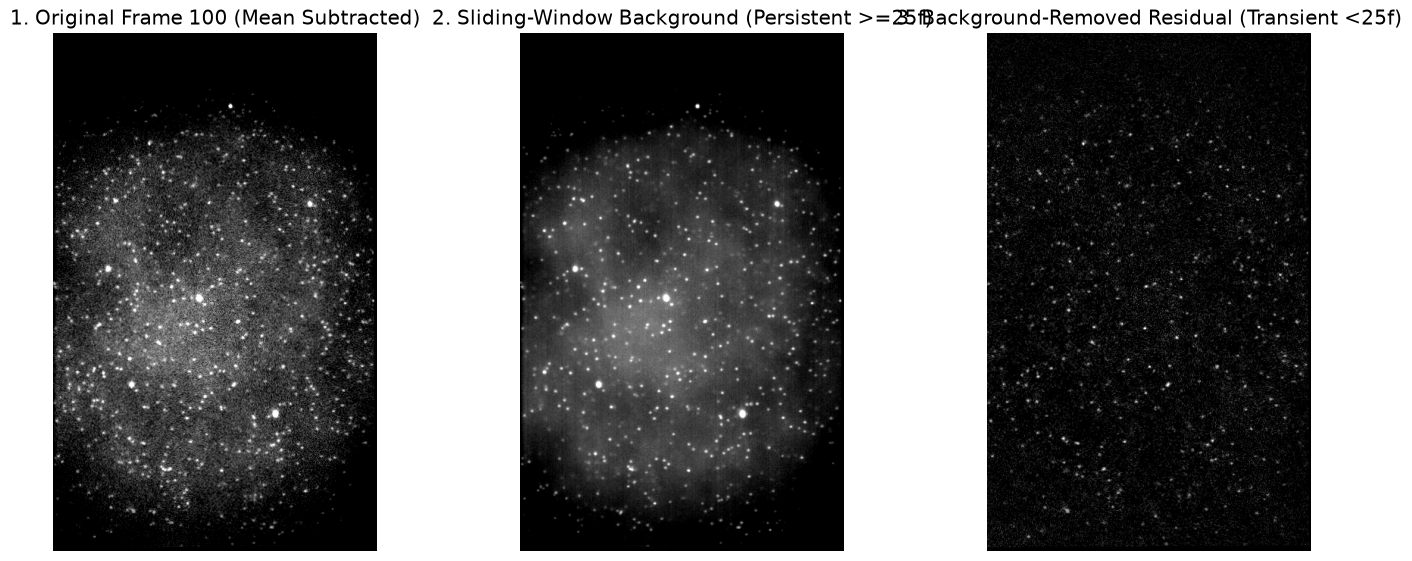

In [5]:
comparison_frame = 100  # zero-based; 49 is the first frame with a full 50-frame window
median_stream = SlidingWindowMedian(window_size=50)

with Image.open(path) as image:
    if not 0 <= comparison_frame < image.n_frames:
        raise ValueError(f'comparison_frame must be between 0 and {image.n_frames - 1}')
    for frame_index in range(comparison_frame + 1):
        image.seek(frame_index)
        comparison_right = np.asarray(image)[:, 428:].astype(np.float32)
        median_background = median_stream.update(comparison_right)

# 1. Original frame (mean-subtracted for display/baseline comparison)
mean_subtracted = np.clip(comparison_right - comparison_right.mean(), 0, comparison_right.max())

# 2. Background-removed residual (transient emitters active < 25 frames)
median_subtracted = np.clip(comparison_right - median_background, 0, comparison_right.max())

# 3. Sliding-window background map (mean-subtracted to match display scale; contains persistent emitters active >= 25 frames)
background_centred = np.clip(median_background - median_background.mean(), 0, median_background.max())

print(f'Frame {comparison_frame}: sliding median uses {median_stream.count} trailing frames')

fig, axes = plt.subplots(1, 3, figsize=(14, 5.5), constrained_layout=True)
for ax, img, title in [
    (axes[0], mean_subtracted, f'1. Original Frame {comparison_frame} (Mean Subtracted)'),
    (axes[1], background_centred, '2. Sliding-Window Background (Persistent >=25f)'),
    (axes[2], median_subtracted, '3. Background-Removed Residual (Transient <25f)'),
]:
    ax.imshow(img, cmap='gray', vmin=0, vmax=display_max)
    ax.set_title(title)
    ax.axis('off')
plt.show()

## 3. Separate Picasso Localisations on Residual vs. Background & Overlay

Here we run Picasso (`localize_frames` with `Box Size = 7`, `Min. Net Gradient = 1000`) independently on:
1. **`median_subtracted` (Background-Removed Residual):** Detects **transient blinking molecules** that were active for fewer than half the frames in the sliding window.
2. **`background_centred` (Sliding-Window Median Background):** Detects **persistent emitters / long-lived fluorophores** that remained ON for at least half the 50-frame window and were therefore extracted into the background image.

We then overlay both localisation sets onto the original frame (`mean_subtracted`) to verify how the two components complement each other.

> [!IMPORTANT]
> **Caveat on Persistent Background Localisations & Intensity-vs-Time ($I(t)$) Tracking:**
> Just because an emitter appears in `median_background` (meaning it was ON for at least $\ge 25$ of the trailing 50 frames) **does not guarantee it is still ON in the current frame (`comparison_frame`)**—for example, it could have been bright during frames `51–80` and bleached/blinked OFF at frame `81`, yet the 50-frame median at frame `100` will still retain its spot!
>
> **Downstream Opportunity (2-Stage Master Molecule Catalogue + $I(t)$ Trace Extraction):**
> Combining residual + sliding-background localisations across the movie gives a complete spatial catalogue of **all** emitter positions (both fast blinkers and long-lived/persistent sites) without losing molecules to the background filter. Once these candidate $(x_i, y_i)$ coordinates are pooled/clustered across time, we can go back to the locally background-corrected stack and extract the raw ROI intensity trace $I_i(t)$ at each molecule's fixed $(x_i, y_i)$ position across all frames—using a step-detector or threshold on $I_i(t)$ to determine the exact frames where each molecule is truly ON vs. OFF.

Do i perhaps test this on the simulations?

Maybe 50 sliding window is too much and maybe 3-5 is good enough, similar to DECODE's temporal context

In [6]:
# Localise on (1) mean-subtracted original, (2) background-removed residual, and (3) sliding-window background
mean_locs = localize_frames(
    mean_subtracted[np.newaxis, :, :],
    info=None, params=params, camera_info=camera_info,
    fitting_method='gausslq', threaded=False,
)

residual_locs = localize_frames(
    median_subtracted[np.newaxis, :, :],
    info=None, params=params, camera_info=camera_info,
    fitting_method='gausslq', threaded=False,
)

background_locs = localize_frames(
    background_centred[np.newaxis, :, :],
    info=None, params=params, camera_info=camera_info,
    fitting_method='gausslq', threaded=False,
)

# Check spatial overlap between transient (residual) and persistent (background) localisations
xy_orig = np.column_stack([mean_locs['x'], mean_locs['y']])
xy_res = np.column_stack([residual_locs['x'], residual_locs['y']])
xy_bg = np.column_stack([background_locs['x'], background_locs['y']])

match_radius_px = 2.0
dist_res_bg = cdist(xy_res, xy_bg)
n_overlap = int((dist_res_bg.min(axis=1) < match_radius_px).sum())

xy_union = np.vstack([xy_res, xy_bg])
n_orig_recovered = int((cdist(xy_orig, xy_union).min(axis=1) < match_radius_px).sum())

print(f'1. Original frame (mean-subtracted) localisations : {len(mean_locs)}')
print(f'2. Background-removed residual (transient <25f)   : {len(residual_locs)}')
print(f'3. Sliding-window background (persistent >=25f)   : {len(background_locs)}')
print(f'   -> Spatial overlap between Residual & Background (<{match_radius_px} px): {n_overlap} spots')
print(f'   -> Original frame spots recovered by (Residual U Background): {n_orig_recovered} / {len(mean_locs)} ({100*n_orig_recovered/len(mean_locs):.1f}%)')

1. Original frame (mean-subtracted) localisations : 601
2. Background-removed residual (transient <25f)   : 319
3. Sliding-window background (persistent >=25f)   : 429
   -> Spatial overlap between Residual & Background (<2.0 px): 18 spots
   -> Original frame spots recovered by (Residual U Background): 553 / 601 (92.0%)


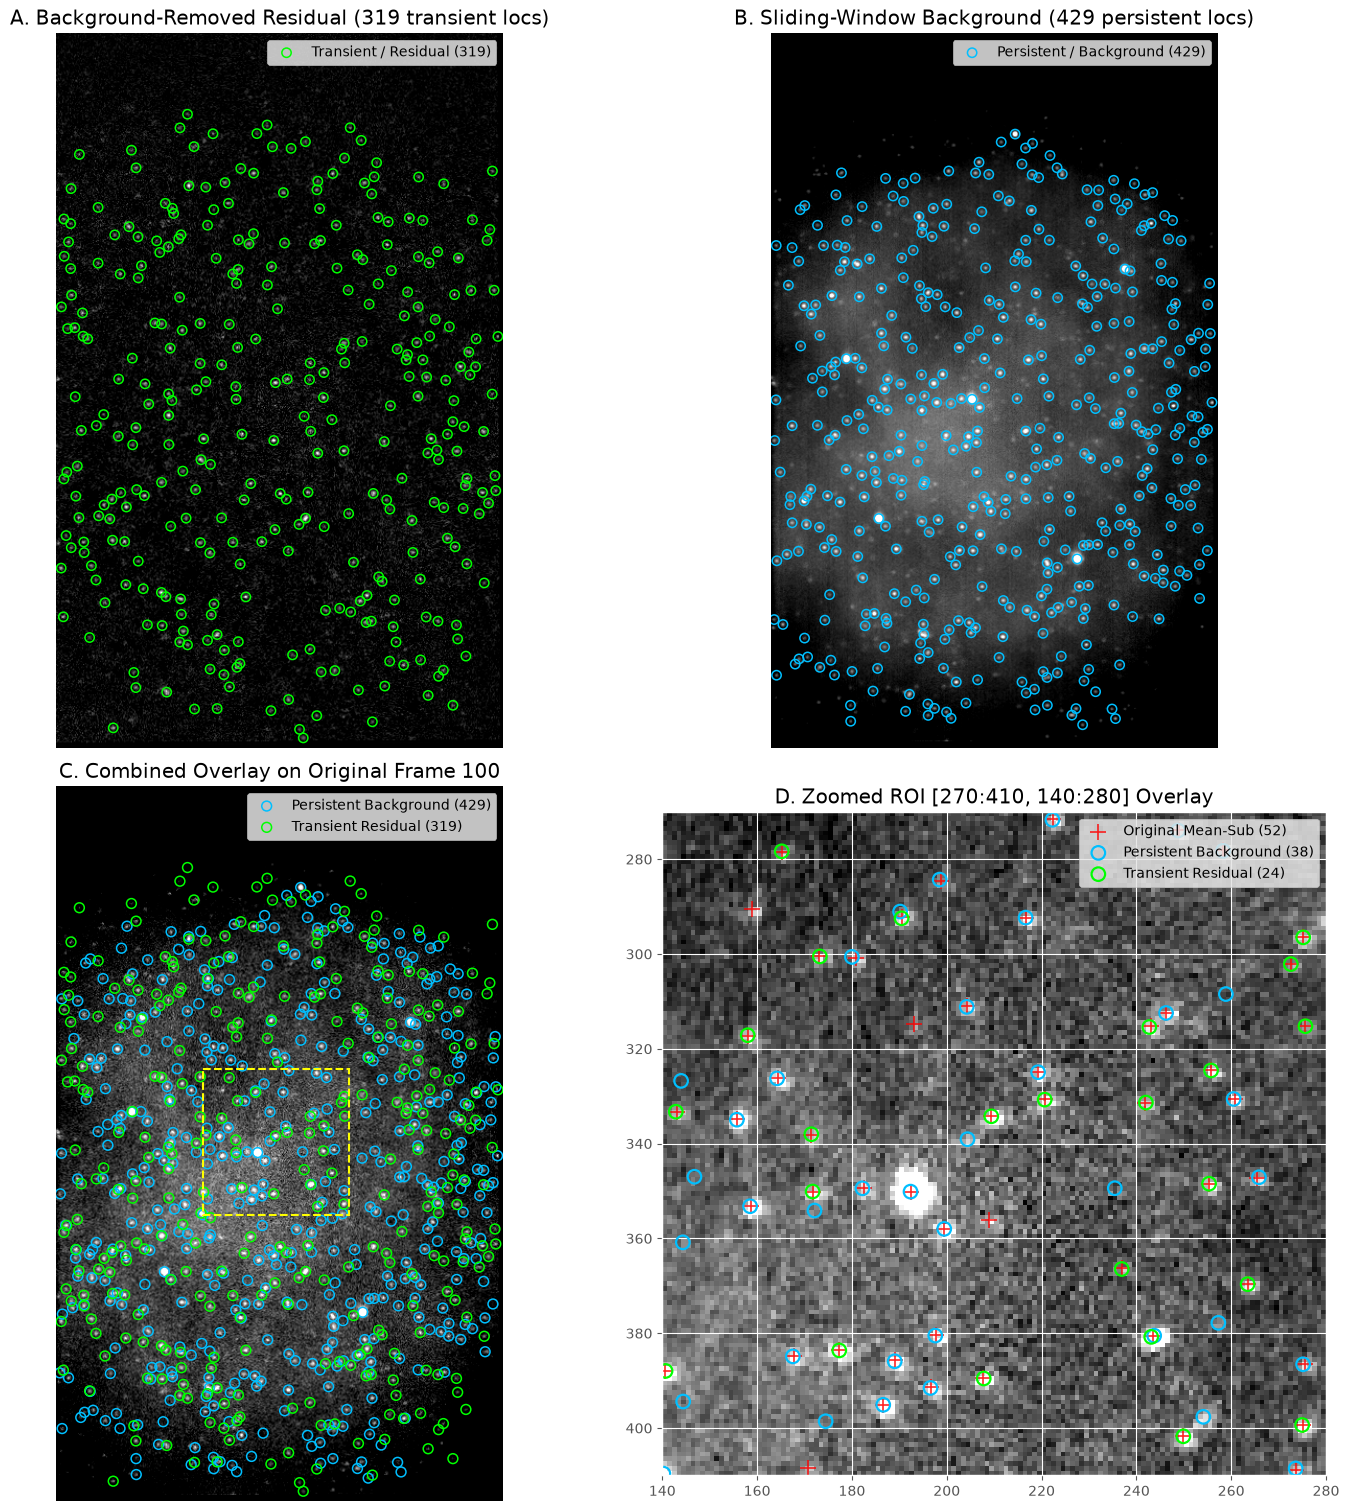

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 15), constrained_layout=True)

# Panel A: Background-removed residual + transient localisations
axes[0, 0].imshow(median_subtracted, cmap='gray', vmin=0, vmax=display_max)
axes[0, 0].scatter(
    residual_locs['x'], residual_locs['y'],
    s=45, facecolors='none', edgecolors='lime', linewidths=1.1,
    label=f'Transient / Residual ({len(residual_locs)})'
)
axes[0, 0].set_title(f'A. Background-Removed Residual ({len(residual_locs)} transient locs)')
axes[0, 0].legend(loc='upper right', framealpha=0.85)
axes[0, 0].axis('off')

# Panel B: Sliding-window background + persistent localisations
axes[0, 1].imshow(background_centred, cmap='gray', vmin=0, vmax=display_max)
axes[0, 1].scatter(
    background_locs['x'], background_locs['y'],
    s=45, facecolors='none', edgecolors='deepskyblue', linewidths=1.1,
    label=f'Persistent / Background ({len(background_locs)})'
)
axes[0, 1].set_title(f'B. Sliding-Window Background ({len(background_locs)} persistent locs)')
axes[0, 1].legend(loc='upper right', framealpha=0.85)
axes[0, 1].axis('off')

# Panel C: Combined Overlay on Original Frame
axes[1, 0].imshow(mean_subtracted, cmap='gray', vmin=0, vmax=display_max)
axes[1, 0].scatter(
    background_locs['x'], background_locs['y'],
    s=50, facecolors='none', edgecolors='deepskyblue', linewidths=1.1,
    label=f'Persistent Background ({len(background_locs)})'
)
axes[1, 0].scatter(
    residual_locs['x'], residual_locs['y'],
    s=50, facecolors='none', edgecolors='lime', linewidths=1.1,
    label=f'Transient Residual ({len(residual_locs)})'
)
axes[1, 0].set_title(f'C. Combined Overlay on Original Frame {comparison_frame}')
axes[1, 0].legend(loc='upper right', framealpha=0.85)
axes[1, 0].axis('off')

# Panel D: Zoomed 140x140 central ROI on Original Frame showing single-molecule partitioning
y0, y1, x0, x1 = 270, 410, 140, 280
# Draw ROI box on Panel C
rect = plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='yellow', linewidth=1.5, linestyle='--')
axes[1, 0].add_patch(rect)

axes[1, 1].imshow(mean_subtracted[y0:y1, x0:x1], cmap='gray', vmin=0, vmax=display_max, extent=[x0, x1, y1, y0])
bg_in_roi = background_locs[(background_locs['x'] >= x0) & (background_locs['x'] <= x1) & (background_locs['y'] >= y0) & (background_locs['y'] <= y1)]
res_in_roi = residual_locs[(residual_locs['x'] >= x0) & (residual_locs['x'] <= x1) & (residual_locs['y'] >= y0) & (residual_locs['y'] <= y1)]
orig_in_roi = mean_locs[(mean_locs['x'] >= x0) & (mean_locs['x'] <= x1) & (mean_locs['y'] >= y0) & (mean_locs['y'] <= y1)]

axes[1, 1].scatter(
    orig_in_roi['x'], orig_in_roi['y'],
    s=130, marker='+', c='red', linewidths=1.2, alpha=0.85,
    label=f'Original Mean-Sub ({len(orig_in_roi)})'
)
axes[1, 1].scatter(
    bg_in_roi['x'], bg_in_roi['y'],
    s=95, facecolors='none', edgecolors='deepskyblue', linewidths=1.6,
    label=f'Persistent Background ({len(bg_in_roi)})'
)
axes[1, 1].scatter(
    res_in_roi['x'], res_in_roi['y'],
    s=95, facecolors='none', edgecolors='lime', linewidths=1.6,
    label=f'Transient Residual ({len(res_in_roi)})'
)
axes[1, 1].set_xlim(x0, x1)
axes[1, 1].set_ylim(y1, y0)
axes[1, 1].set_title(f'D. Zoomed ROI [{y0}:{y1}, {x0}:{x1}] Overlay')
axes[1, 1].legend(loc='upper right', framealpha=0.85)
plt.show()

## 4. Multi-Frame Statistics & DECODE Photon Conversion

To estimate parameters for the DECODE simulation (`background_photons` and `brightness_mean_std`), we advance the sliding-window median stream across `stats_additional_frames = 100` additional frames and localise the residual image every `stats_localise_stride = 10` frames.

Processed frame 125/200
Processed frame 150/200
Processed frame 175/200
Processed frame 200/200
Background spatial median (5th-95th percentile): 675.50 to 693.00 ADU/pixel
Fitted spot brightness: mean 1346.96, std 767.42 ADU
Fitted spot brightness percentiles (5, 50, 95): [ 575.24 1203.75 2566.42]


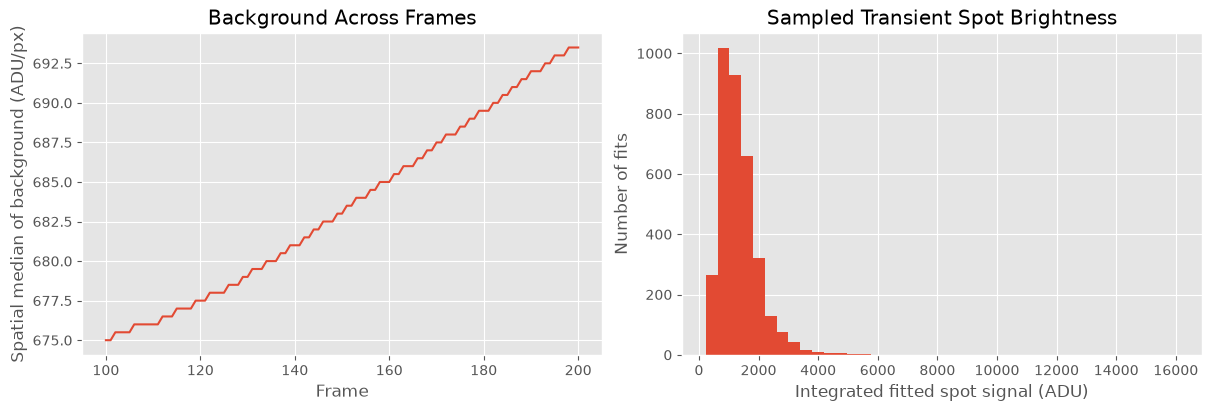

In [8]:
stats_additional_frames = 100
stats_localise_stride = 10

adu_camera = {'Baseline': 0, 'Sensitivity': 1.0, 'Gain': 1, 'Pixelsize': 117}
background_frames = []
background_levels_adu = []
brightness_samples_adu = []
localisation_counts = []

def record_statistics(index, raw_right, background):
    background_frames.append(index)
    background_levels_adu.append(float(np.median(background)))
    if (index - comparison_frame) % stats_localise_stride == 0:
        residual = np.clip(raw_right - background, 0, raw_right.max())
        locs = localize_frames(
            residual[np.newaxis, :, :], info=None, params=params,
            camera_info=adu_camera, fitting_method='gausslq', threaded=False
        )
        values = np.asarray(locs['photons'], dtype=float)
        valid = values[np.isfinite(values) & (values > 0)]
        brightness_samples_adu.extend(valid.tolist())
        localisation_counts.append((index, len(valid)))

record_statistics(comparison_frame, comparison_right, median_background)
with Image.open(path) as image:
    stats_last_frame = min(comparison_frame + stats_additional_frames, image.n_frames - 1)
    for index in range(comparison_frame + 1, stats_last_frame + 1):
        image.seek(index)
        right_frame = np.asarray(image)[:, 428:].astype(np.float32)
        background = median_stream.update(right_frame)
        record_statistics(index, right_frame, background)
        if (index - comparison_frame) % 25 == 0:
            print(f'Processed frame {index}/{stats_last_frame}')

background_levels_adu = np.asarray(background_levels_adu)
brightness_samples_adu = np.asarray(brightness_samples_adu)
background_range_adu = np.percentile(background_levels_adu, [5, 95])

print(f'Background spatial median (5th-95th percentile): {background_range_adu[0]:.2f} to {background_range_adu[1]:.2f} ADU/pixel')
print(f'Fitted spot brightness: mean {brightness_samples_adu.mean():.2f}, std {brightness_samples_adu.std(ddof=1):.2f} ADU')
print(f'Fitted spot brightness percentiles (5, 50, 95): {np.percentile(brightness_samples_adu, [5, 50, 95]).round(2)}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(background_frames, background_levels_adu)
axes[0].set(xlabel='Frame', ylabel='Spatial median of background (ADU/px)', title='Background Across Frames')
axes[1].hist(brightness_samples_adu, bins=40)
axes[1].set(xlabel='Integrated fitted spot signal (ADU)', ylabel='Number of fits', title='Sampled Transient Spot Brightness')
plt.show()

In [9]:
# Convert from camera ADU to DECODE photon units using Nanoimager sCMOS parameters
camera_baseline_adu = 400.0   # Measured dark offset in ADU for ONI Nanoimager
electrons_per_adu = 0.46      # sCMOS conversion factor (e-/ADU)
quantum_efficiency = 0.8      # QE

factor = electrons_per_adu / quantum_efficiency
background_photons_estimate = (background_range_adu - camera_baseline_adu) * factor
brightness_mean_std_estimate = [
    float(brightness_samples_adu.mean() * factor),
    float(brightness_samples_adu.std(ddof=1) * factor),
]

print('Candidate background_photons (5th-95th percentile):', background_photons_estimate.round(2).tolist(), 'photons/pixel')
print('Candidate brightness_mean_std:', np.round(brightness_mean_std_estimate, 2).tolist(), 'photons')

Candidate background_photons (5th-95th percentile): [158.41, 168.48] photons/pixel
Candidate brightness_mean_std: [774.5, 441.27] photons
